# 02 - Linkage simulation: when $(3+1)^n$ breaks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/USER/project-23-link/blob/main/notebooks/02_linkage_simulation.ipynb)

We simulate meiosis along chromosomes with the Haldane map function ($r = \tfrac12(1-e^{-2d})$) and compare the distribution of dominant phenotypes among offspring of $Aa \times Aa$ parents (both with all $A$ on one haplotype, i.e. coupling) with the ideal $\mathrm{Binomial}(23, 0.75)$.

**Important:** one locus per chromosome means independent assortment by construction, so linkage can only appear when several loci share a chromosome.

In [1]:
import sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/USER/project-23-link.git"  # <- replace USER

def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "link23").exists():
            return q
    return None

ROOT = find_root()
if ROOT is None:  # e.g. Google Colab: clone the repo first
    subprocess.run(["git", "clone", REPO_URL, "project-23-link"], check=True)
    ROOT = Path("project-23-link").resolve()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from link23 import *
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(23)

## A. Control: 23 loci, one per chromosome

This is the setting of the original note. The simulation must reproduce the binomial. Sampling noise sets the baseline for the divergence measures.

In [2]:
N = 200_000
ref = binomial_pmf(23)

def summarize(counts, label=""):
    e = empirical_pmf(counts, 23)
    return dict(label=label, mean=counts.mean(), var=counts.var(),
                entropy=shannon_entropy(e), kl=kl_divergence(e, ref),
                tv=total_variation(e, ref), bc=bimodality_coefficient(counts))

loci_A = make_loci(np.arange(23), np.zeros(23))
cA = simulate_offspring_counts(loci_A, N, rng)
base = summarize(rng.binomial(23, .75, N), "pure binomial sample")
A = summarize(cA, "23 chromosomes, 1 locus each")
for r in (base, A):
    print(f"{r['label']:32s} mean={r['mean']:.3f} var={r['var']:.3f} H={r['entropy']:.3f} bits KL={r['kl']:.5f} TV={r['tv']:.4f}")
print("theory: mean 17.25, var 4.3125, entropy(Bin) =", round(shannon_entropy(ref), 3), "bits")

pure binomial sample             mean=17.254 var=4.305 H=3.091 bits KL=0.00006 TV=0.0028
23 chromosomes, 1 locus each     mean=17.244 var=4.305 H=3.092 bits KL=0.00005 TV=0.0028
theory: mean 17.25, var 4.3125, entropy(Bin) = 3.093 bits


## B. All 23 loci on a single chromosome, varying spacing

Spacing 0 cM means complete linkage (all-or-nothing); large spacing approaches independence. Total span = $22 \times$ spacing, so 10 cM already covers 220 cM, about one large chromosome.

In [3]:
spacings = [0, 0.1, 0.5, 1, 2, 5, 10]
resB = []
for s in spacings:
    loci = make_loci(np.zeros(23), np.arange(23) * s)
    c = simulate_offspring_counts(loci, N, rng)
    resB.append((s, c, summarize(c, f"{s} cM")))

print(f"{'spacing':>8} {'var':>8} {'entropy':>8} {'KL(bits)':>9} {'TV':>7} {'bimodality':>10}")
for s, c, r in resB:
    print(f"{s:>6} cM {r['var']:8.2f} {r['entropy']:8.3f} {r['kl']:9.3f} {r['tv']:7.3f} {r['bc']:10.3f}")

 spacing      var  entropy  KL(bits)      TV bimodality
     0 cM    98.56    0.808    17.766   0.999      1.000
   0.1 cM    97.02    1.030    17.281   0.986      0.991
   0.5 cM    89.37    1.620    15.447   0.940      0.955
     1 cM    81.79    2.117    13.709   0.892      0.915
     2 cM    69.41    2.766    11.038   0.818      0.848
     5 cM    46.48    3.626     6.434   0.658      0.705
    10 cM    29.20    3.970     3.252   0.509      0.579


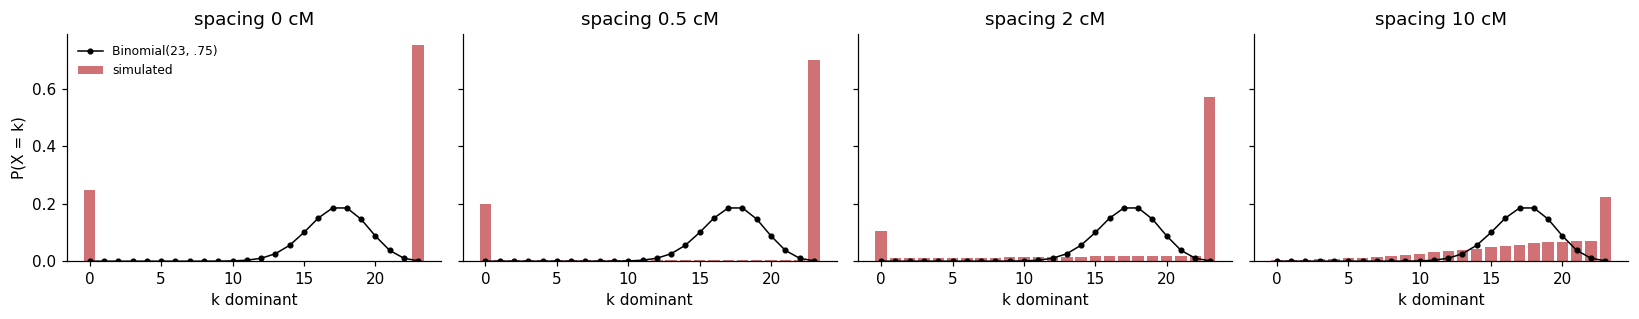

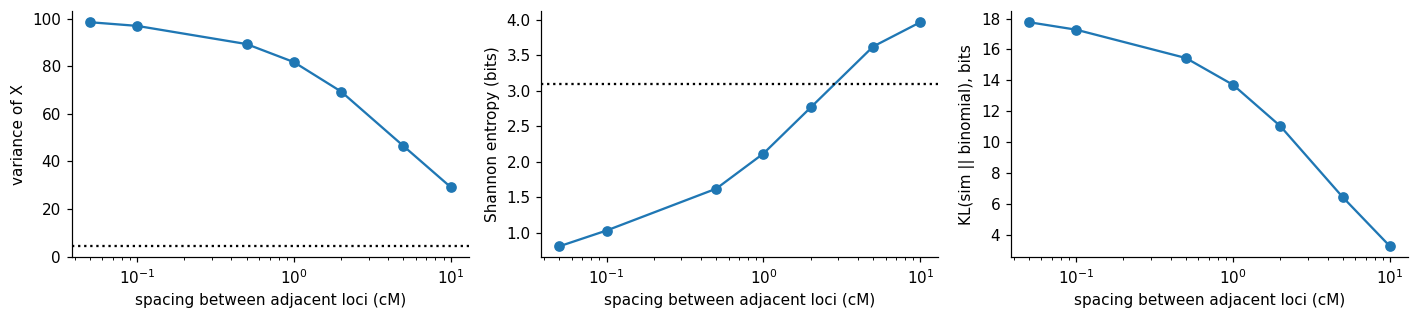

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, (s, c, r) in zip(axes, [resB[0], resB[2], resB[4], resB[6]]):
    ax.bar(np.arange(24), empirical_pmf(c, 23), color="#C44E52", alpha=.8, label="simulated")
    ax.plot(np.arange(24), ref, "k.-", lw=1, label="Binomial(23, .75)")
    ax.set_title(f"spacing {s} cM"); ax.set_xlabel("k dominant")
axes[0].set_ylabel("P(X = k)"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "02_linkage_histograms.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(13, 3))
xs = [max(s, 0.05) for s in spacings]
ax[0].semilogx(xs, [r["var"] for _, _, r in resB], "o-"); ax[0].axhline(4.3125, color="k", ls=":"); ax[0].set_ylabel("variance of X")
ax[1].semilogx(xs, [r["entropy"] for _, _, r in resB], "o-"); ax[1].axhline(shannon_entropy(ref), color="k", ls=":"); ax[1].set_ylabel("Shannon entropy (bits)")
ax[2].semilogx(xs, [r["kl"] for _, _, r in resB], "o-"); ax[2].set_ylabel("KL(sim || binomial), bits")
for a in ax: a.set_xlabel("spacing between adjacent loci (cM)")
plt.tight_layout(); plt.savefig(FIG / "02_linkage_metrics.png", bbox_inches="tight"); plt.show()

Linkage **raises** the variance (loci move together) and the distribution polarizes toward the extremes: at complete linkage only 0 or 23 dominant phenotypes occur (bimodality coefficient close to 1).

**Careful with entropy.** The Shannon entropy of the *count* $X$ is not monotonic: it first rises above the binomial value (the distribution gets wider) and only collapses at tight linkage. The loss of entropy caused by linkage is a property of the *joint* genotype distribution, not of this one-dimensional summary.

## C. The chromosome as the unit of independence

Keep 23 loci, 1 cM apart inside a chromosome, but spread them over $m$ chromosomes. The fewer the chromosomes, the fewer independent blocks, and the larger the variance. This is the honest version of 'the chromosome structure limits Mendelian randomness': it is a statement about the *effective number of independent blocks*, not a physical ceiling.

m= 1 chromosomes  var=81.86  KL=13.7349 bits  entropy=2.105


m= 2 chromosomes  var=45.15  KL=7.5079 bits  entropy=2.658


m= 3 chromosomes  var=31.09  KL=4.8787 bits  entropy=2.928


m= 5 chromosomes  var=19.54  KL=2.5657 bits  entropy=3.195
m=12 chromosomes  var=8.28  KL=0.3510 bits  entropy=3.414


m=23 chromosomes  var=4.30  KL=0.0000 bits  entropy=3.092


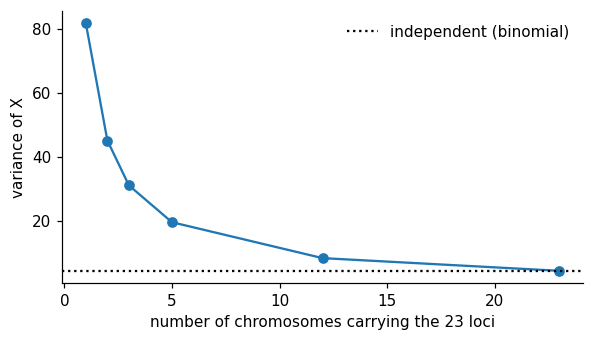

In [5]:
ms = [1, 2, 3, 5, 12, 23]
resC = []
for m in ms:
    chrom = np.repeat(np.arange(m), int(np.ceil(23 / m)))[:23]
    pos = np.concatenate([np.arange((chrom == c).sum()) * 1.0 for c in range(m)])
    loci = make_loci(chrom, pos)
    c = simulate_offspring_counts(loci, N, rng)
    resC.append((m, summarize(c, f"{m} chromosomes")))
    print(f"m={m:>2} chromosomes  var={resC[-1][1]['var']:.2f}  KL={resC[-1][1]['kl']:.4f} bits  entropy={resC[-1][1]['entropy']:.3f}")

plt.figure(figsize=(5.5, 3.2))
plt.plot(ms, [r["var"] for _, r in resC], "o-")
plt.axhline(4.3125, color="k", ls=":", label="independent (binomial)")
plt.xlabel("number of chromosomes carrying the 23 loci"); plt.ylabel("variance of X"); plt.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "02_effective_blocks.png", bbox_inches="tight"); plt.show()

## D. Linkage is not linkage disequilibrium

* **Linkage**: co-segregation within a family or cross, controlled by $r$ (what we simulated above).
* **Linkage disequilibrium (LD)**: non-random association of alleles in a *population*. It is created by history (drift, selection, admixture, mutation) and then decays with generations at a rate set by $r$: $D_t = D_0 (1 - r)^t$.

The curve below is the analytic decay of LD, not a simulation of a population.

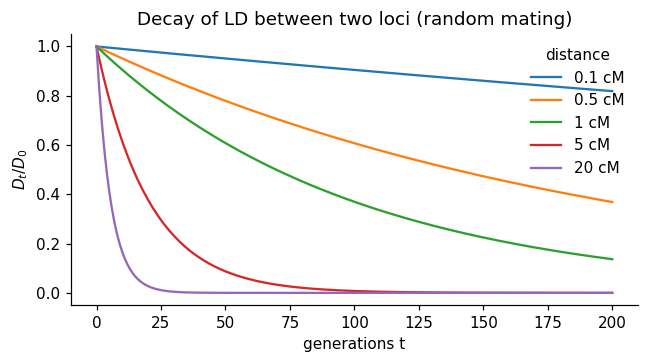

In [6]:
t = np.arange(0, 201)
plt.figure(figsize=(6, 3.4))
for d in [0.1, 0.5, 1, 5, 20]:
    plt.plot(t, (1 - haldane_r(d)) ** t, label=f"{d} cM")
plt.xlabel("generations t"); plt.ylabel("$D_t / D_0$"); plt.legend(title="distance", frameon=False)
plt.title("Decay of LD between two loci (random mating)")
plt.tight_layout(); plt.savefig(FIG / "02_ld_decay.png", bbox_inches="tight"); plt.show()

## Limits and next steps

* Map lengths in `genome.py` are rounded approximations; no crossover interference, no sex-specific maps.
* Both parents are modelled with the same phase; a random-phase option exists (`phase='random'`).
* This is a *family cross* model. Population LD needs forward simulation (`msprime`, `stdpopsim`, SLiM) and real data (1000 Genomes).
* Pharmacogenomic clustering is dominated by specific variants and diplotypes (CYP2D6, CYP2C19...), which would be the clinical use case to add.